# Importing the Datasets, Plotting the histograms

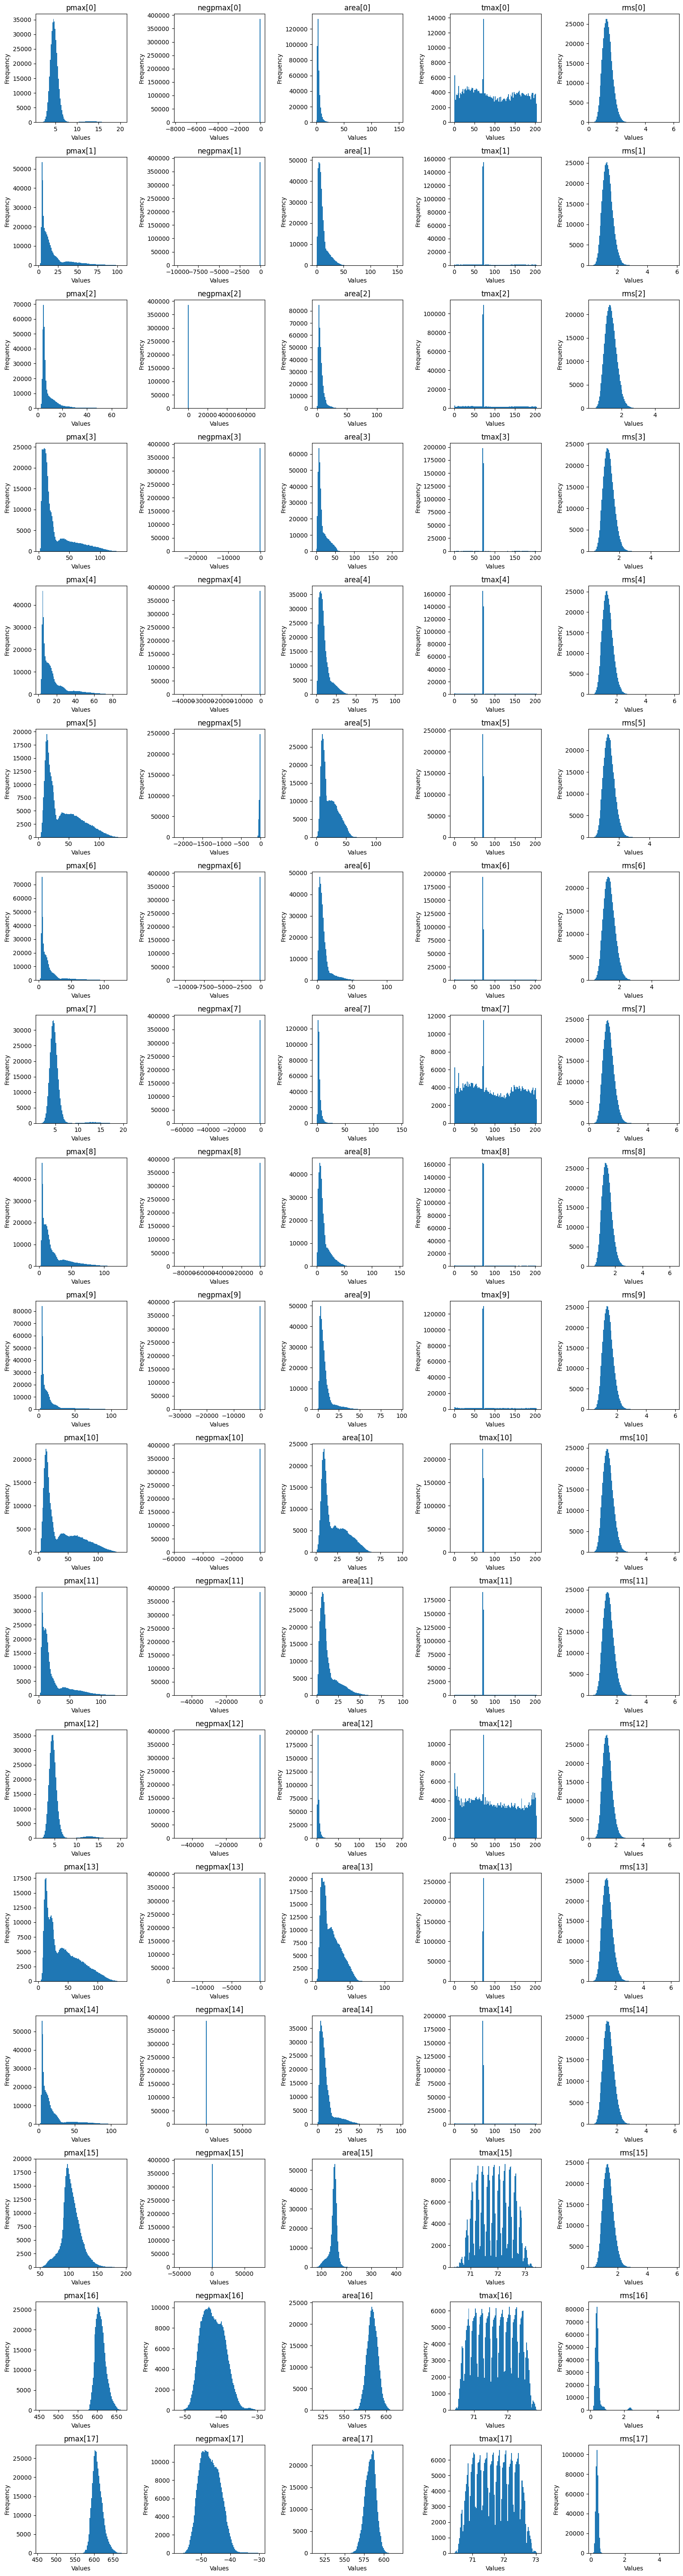

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

dfDevelopment = pd.read_csv("data/development.csv")
dfEvaluation = pd.read_csv("data/evaluation.csv")

plt.figure(figsize=(16, 60))

for i, column in enumerate(dfDevelopment.columns[2:], start = 1):
    plt.subplot(18, 5, i)
    plt.hist(dfDevelopment[column], bins = 100)
    plt.title(column)
    plt.xlabel('Values')
    plt.ylabel('Frequency')
    plt.tight_layout()

plt.show()

# Excluding Noises

In [2]:
dfDevelopment2 = dfDevelopment.drop(columns = ['pmax[0]', 'negpmax[0]', 'area[0]', 'tmax[0]', 'rms[0]', 'pmax[7]', 'negpmax[7]', 'area[7]', 'tmax[7]', 'rms[7]', 'pmax[12]', 'negpmax[12]', 'area[12]', 'tmax[12]', 'rms[12]', 'pmax[15]', 'negpmax[15]', 'area[15]', 'tmax[15]', 'rms[15]', 'pmax[16]', 'negpmax[16]', 'area[16]', 'tmax[16]', 'rms[16]', 'pmax[17]', 'negpmax[17]', 'area[17]', 'tmax[17]', 'rms[17]'])
dfEvaluation2 = dfEvaluation.drop(columns = ['pmax[0]', 'negpmax[0]', 'area[0]', 'tmax[0]', 'rms[0]', 'pmax[7]', 'negpmax[7]', 'area[7]', 'tmax[7]', 'rms[7]', 'pmax[12]', 'negpmax[12]', 'area[12]', 'tmax[12]', 'rms[12]', 'pmax[15]', 'negpmax[15]', 'area[15]', 'tmax[15]', 'rms[15]', 'pmax[16]', 'negpmax[16]', 'area[16]', 'tmax[16]', 'rms[16]', 'pmax[17]', 'negpmax[17]', 'area[17]', 'tmax[17]', 'rms[17]'])

# Grid Search

it takes hours to run the snippet below, so I have commented it out.

In [ ]:
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import GridSearchCV

# gridSearch = {
#     'n_estimators': [20],
#     'max_depth': [None, 10, 20, 30],
#     'min_samples_split': [2, 5, 10],
#     'min_samples_leaf': [1, 2, 4]
# }

# rf = RandomForestClassifier()
# gridSearch2 = GridSearchCV(estimator=rf, param_grid = gridSearch, cv = 5, n_jobs = -1, verbose = 3)
# gridSearch2.fit(dfDevelopment2.iloc[:, 2:], dfDevelopment2.iloc[:, 1])
# print("The Best: ", gridSearch2.best_params_)

# Random Forest Regressor

In [3]:
y = dfDevelopment2.iloc[:, :2]
X = dfDevelopment2.iloc[:, 2:]
rf = RandomForestRegressor(n_estimators = 1500, min_samples_split = 5, min_samples_leaf = 2, random_state = 9, max_features = 'sqrt', max_depth = 30, n_jobs= -1)
rf.fit(X, y)

RandomForestRegressor(max_depth=30, max_features='sqrt', min_samples_leaf=2,
                      min_samples_split=5, n_estimators=1500, n_jobs=-1,
                      random_state=9)

# Result

In [7]:
predics = rf.predict(dfEvaluation2.iloc[:, 1:])
predicsFormat = ['|'.join(map(str, pred)) for pred in predics]
finalResult = pd.DataFrame({'Id': dfEvaluation2.index, 'Predicted': predicsFormat})
finalResult.to_csv("finalResult.csv", index = False)